# End-to-End Machine Learning Exercise


**Prepared by:** **Ali H. El-Kassas**  
*Senior Data Scientist | Machine Learning Instructor*

This notebook is intended to help students practice the complete machine learning workflow, including exploratory data analysis, data preprocessing, feature engineering, model training, hyperparameter tuning, and error analysis.

Complete all `TODO` sections.

### Objectives

Build a machine learning pipeline that predicts the Manufacturer Suggested Retail Price (MSRP) of a car.

- Frame the problem
- Select a Performance Measure
- Quick look on the data
- Train/Validation/Test split
- EDA
- Preprocessing
- Pipelines
- Modeling
- Fine-Tuning
- Error Analysis
- Final Evaluation
- Deploy the model

In [1]:
# TODO Import all the lib that you need here
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split

In [2]:
# TODO: Load the dataset
df = pd.read_csv("data.csv")

df.head()

,Make,Model,Year,Engine Fuel Type,Engine HP,Engine Cylinders,Transmission Type,Driven_Wheels,Number of Doors,Market Category,Vehicle Size,Vehicle Style,highway MPG,city mpg,Popularity,MSRP
0,BMW,1 Series M,2011,premium unleaded (required),335.0,6.0,MANUAL,rear wheel drive,2.0,"Factory Tuner,Luxury,High-Performance",Compact,Coupe,26,19,3916,46135
1,BMW,1 Series,2011,premium unleaded (required),300.0,6.0,MANUAL,rear wheel drive,2.0,"Luxury,Performance",Compact,Convertible,28,19,3916,40650
2,BMW,1 Series,2011,premium unleaded (required),300.0,6.0,MANUAL,rear wheel drive,2.0,"Luxury,High-Performance",Compact,Coupe,28,20,3916,36350
3,BMW,1 Series,2011,premium unleaded (required),230.0,6.0,MANUAL,rear wheel drive,2.0,"Luxury,Performance",Compact,Coupe,28,18,3916,29450
4,BMW,1 Series,2011,premium unleaded (required),230.0,6.0,MANUAL,rear wheel drive,2.0,Luxury,Compact,Convertible,28,18,3916,34500


## Initial Inspection
Inspect shape, dtypes, missing values, duplicates and descriptive statistics.

In [4]:
# TODO
df.shape

(11914, 16)

In [5]:
# TODO
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 11914 entries, 0 to 11913
Data columns (total 16 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Make               11914 non-null  object 
 1   Model              11914 non-null  object 
 2   Year               11914 non-null  int64  
 3   Engine Fuel Type   11911 non-null  object 
 4   Engine HP          11845 non-null  float64
 5   Engine Cylinders   11884 non-null  float64
 6   Transmission Type  11914 non-null  object 
 7   Driven_Wheels      11914 non-null  object 
 8   Number of Doors    11908 non-null  float64
 9   Market Category    8172 non-null   object 
 10  Vehicle Size       11914 non-null  object 
 11  Vehicle Style      11914 non-null  object 
 12  highway MPG        11914 non-null  int64  
 13  city mpg           11914 non-null  int64  
 14  Popularity         11914 non-null  int64  
 15  MSRP               11914 non-null  int64  
dtypes: float64(3), int64(5

In [6]:
df.describe()

,Year,Engine HP,Engine Cylinders,Number of Doors,highway MPG,city mpg,Popularity,MSRP
count,11914.000000,11845.00000,11884.000000,11908.000000,11914.000000,11914.000000,11914.000000,1.191400e+04
mean,2010.384338,249.38607,5.628829,3.436093,26.637485,19.733255,1554.911197,4.059474e+04
std,7.579740,109.19187,1.780559,0.881315,8.863001,8.987798,1441.855347,6.010910e+04
min,1990.000000,55.00000,0.000000,2.000000,12.000000,7.000000,2.000000,2.000000e+03
25%,2007.000000,170.00000,4.000000,2.000000,22.000000,16.000000,549.000000,2.100000e+04
50%,2015.000000,227.00000,6.000000,4.000000,26.000000,18.000000,1385.000000,2.999500e+04
75%,2016.000000,300.00000,6.000000,4.000000,30.000000,22.000000,2009.000000,4.223125e+04
max,2017.000000,1001.00000,16.000000,4.000000,354.000000,137.000000,5657.000000,2.065902e+06


In [7]:
df.isnull().sum().sort_values(ascending=False)

Market Category      3742
Engine HP              69
Engine Cylinders       30
Number of Doors         6
Engine Fuel Type        3
Make                    0
Model                   0
Year                    0
Transmission Type       0
Driven_Wheels           0
Vehicle Size            0
Vehicle Style           0
highway MPG             0
city mpg                0
Popularity              0
MSRP                    0
dtype: int64

In [8]:
(df.isnull().sum() / len(df) * 100).sort_values(ascending=False)

Market Category      31.408427
Engine HP             0.579151
Engine Cylinders      0.251805
Number of Doors       0.050361
Engine Fuel Type      0.025180
Make                  0.000000
Model                 0.000000
Year                  0.000000
Transmission Type     0.000000
Driven_Wheels         0.000000
Vehicle Size          0.000000
Vehicle Style         0.000000
highway MPG           0.000000
city mpg              0.000000
Popularity            0.000000
MSRP                  0.000000
dtype: float64

In [9]:
df.duplicated().sum()

715

In [10]:
df["MSRP"].describe()

count    1.191400e+04
mean     4.059474e+04
std      6.010910e+04
min      2.000000e+03
25%      2.100000e+04
50%      2.999500e+04
75%      4.223125e+04
max      2.065902e+06
Name: MSRP, dtype: float64

In [11]:
df = df.drop_duplicates().copy()

df.shape

(11199, 16)

## Train / Validation / Test Split
Split data into Train, Validation and Test sets.

In [29]:
# TODO
X = df.drop(columns=["MSRP"])
y = df["MSRP"]

In [31]:
from sklearn.model_selection import train_test_split

X_train_val, X_test, y_train_val, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

In [33]:
X_train, X_val, y_train, y_val = train_test_split(
    X_train_val, y_train_val,
    test_size=0.2,
    random_state=42
)

In [35]:
print("Training:", X_train.shape, y_train.shape)
print("Validation:", X_val.shape, y_val.shape)
print("Testing:", X_test.shape, y_test.shape)

Training: (7167, 15) (7167,)
Validation: (1792, 15) (1792,)
Testing: (2240, 15) (2240,)


In [37]:
train_df = X_train.copy()
train_df["MSRP"] = y_train

## Exploratory Data Analysis

### Numerical Features



- Histograms
- KDE plots
- Boxplots
- Distribution of MSRP
- Identify skewed features

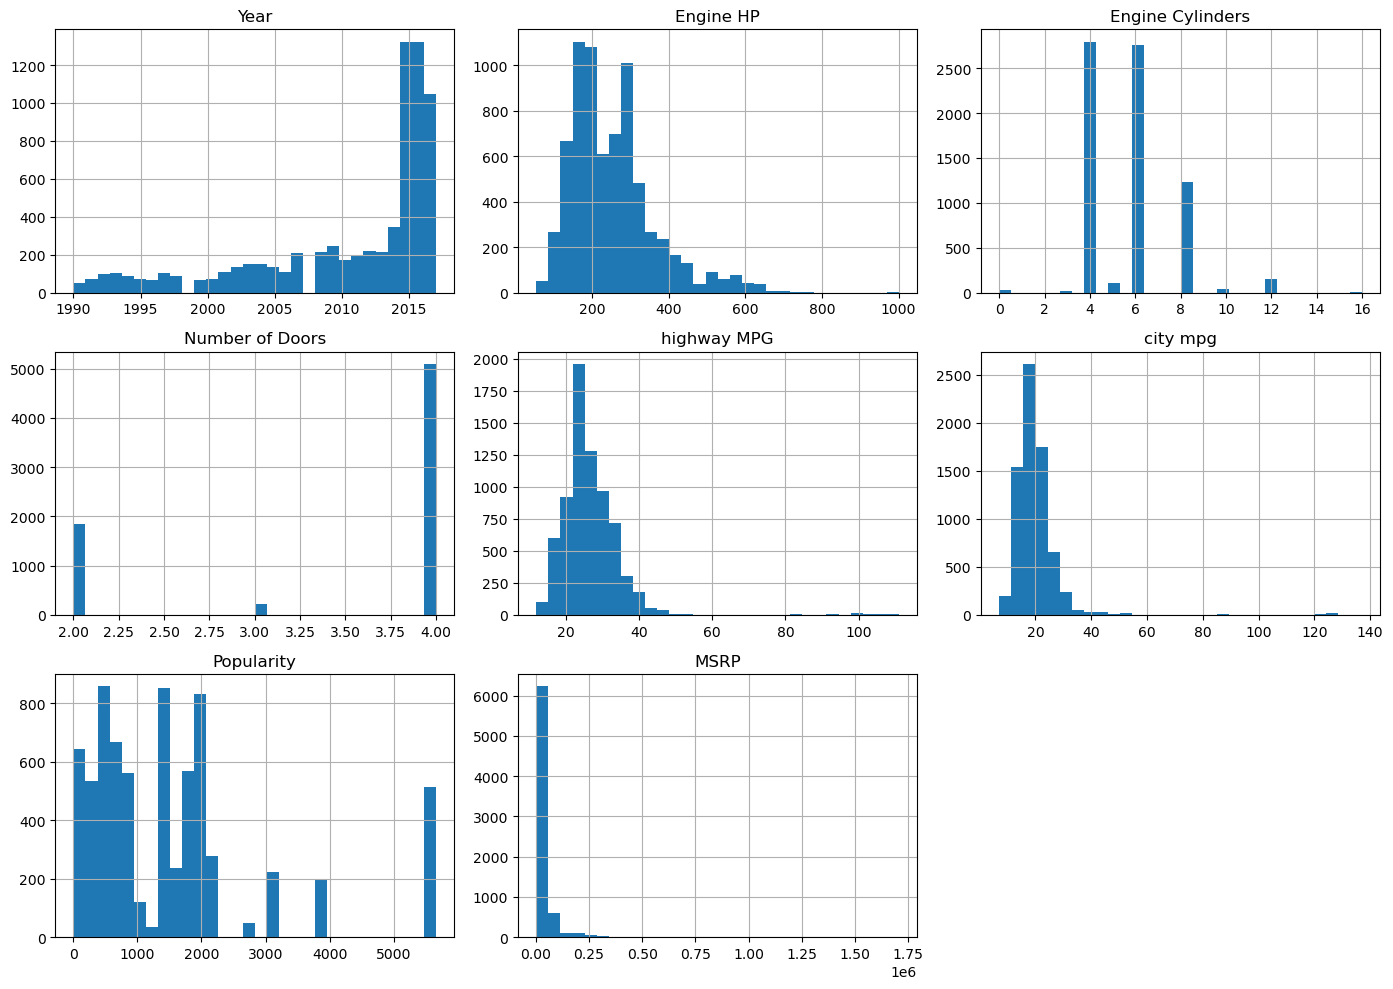

In [41]:
# TODO
train_df.hist(figsize=(14, 10), bins=30)

plt.tight_layout()
plt.show()

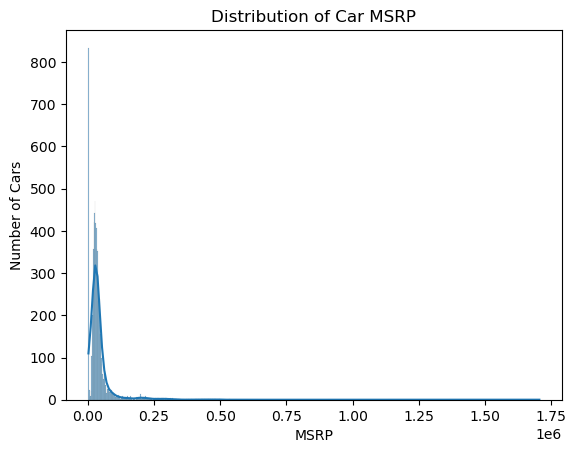

In [42]:
sns.histplot(train_df["MSRP"], kde=True)

plt.title("Distribution of Car MSRP")
plt.xlabel("MSRP")
plt.ylabel("Number of Cars")
plt.show()

In [43]:
train_df.select_dtypes(include=["int64", "float64"]).skew().sort_values(ascending=False)

MSRP                10.206293
city mpg             7.121412
highway MPG          4.176388
Popularity           1.625165
Engine HP            1.214128
Engine Cylinders     0.965023
Number of Doors     -1.016482
Year                -1.273694
dtype: float64

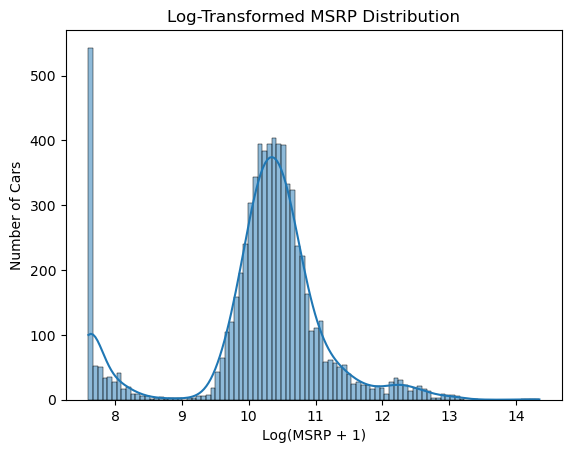

In [45]:
sns.histplot(np.log1p(train_df["MSRP"]), kde=True)

plt.title("Log-Transformed MSRP Distribution")
plt.xlabel("Log(MSRP + 1)")
plt.ylabel("Number of Cars")
plt.show()

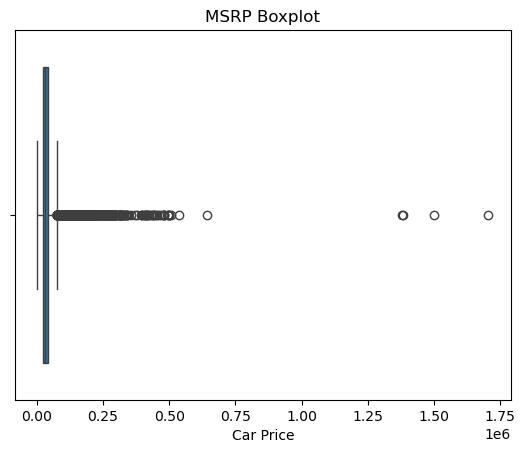

In [46]:
sns.boxplot(x=train_df["MSRP"])

plt.title("MSRP Boxplot")
plt.xlabel("Car Price")
plt.show()

In [49]:
train_df.sort_values("MSRP", ascending=False)[
    ["Make", "Model", "Year", "Engine HP", "MSRP"]
].head(10)

,Make,Model,Year,Engine HP,MSRP
11364,Bugatti,Veyron 16.4,2009,1001.0,1705769
8486,Lamborghini,Reventon,2008,650.0,1500000
6351,Maybach,Landaulet,2012,620.0,1382750
6350,Maybach,Landaulet,2011,620.0,1380000
4024,Ferrari,Enzo,2003,660.0,643330
1629,Lamborghini,Aventador,2016,750.0,535500
698,Maybach,62,2010,631.0,506500
1623,Lamborghini,Aventador,2014,720.0,497650
1627,Lamborghini,Aventador,2015,720.0,497650
9683,Mercedes-Benz,SLR McLaren,2008,617.0,495000


## Outlier Detection


- Identify outliers using boxplots
- Decide whether to remove them and explain why?

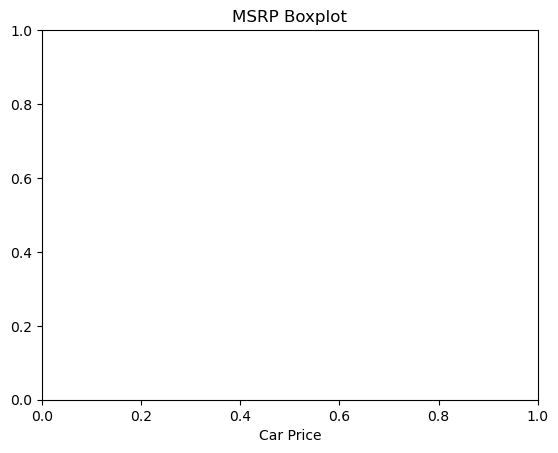

In [54]:
# TODOsns.boxplot(x=train_df["MSRP"])

plt.title("MSRP Boxplot")
plt.xlabel("Car Price")
plt.show()

### will not remove them because Deleting every expensive vehicle would reduce the range of cars our model can learn to predict.

In [57]:
train_df.sort_values("MSRP", ascending=False)[
    ["Make", "Model", "Year", "Engine HP", "MSRP"]
].head(10)

,Make,Model,Year,Engine HP,MSRP
11364,Bugatti,Veyron 16.4,2009,1001.0,1705769
8486,Lamborghini,Reventon,2008,650.0,1500000
6351,Maybach,Landaulet,2012,620.0,1382750
6350,Maybach,Landaulet,2011,620.0,1380000
4024,Ferrari,Enzo,2003,660.0,643330
1629,Lamborghini,Aventador,2016,750.0,535500
698,Maybach,62,2010,631.0,506500
1623,Lamborghini,Aventador,2014,720.0,497650
1627,Lamborghini,Aventador,2015,720.0,497650
9683,Mercedes-Benz,SLR McLaren,2008,617.0,495000


In [59]:
train_df.sort_values("MSRP")[
    ["Make", "Model", "Year", "Engine HP", "MSRP"]
].head(10)

,Make,Model,Year,Engine HP,MSRP
3321,Oldsmobile,Cutlass Ciera,1993,160.0,2000
7135,Mazda,Navajo,1992,155.0,2000
3813,Oldsmobile,Eighty-Eight Royale,1993,170.0,2000
3324,Oldsmobile,Cutlass Ciera,1994,160.0,2000
6414,Acura,Legend,1993,200.0,2000
687,Mazda,626,2000,130.0,2000
9161,Dodge,Shadow,1993,100.0,2000
3036,Volvo,Coupe,1991,188.0,2000
908,Saab,900,1998,185.0,2000
6353,Plymouth,Laser,1992,135.0,2000


In [61]:
Q1 = train_df["MSRP"].quantile(0.25)
Q3 = train_df["MSRP"].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

print("Lower bound:", lower_bound)
print("Upper bound:", upper_bound)

print("Outliers:", (
    (train_df["MSRP"] < lower_bound) |
    (train_df["MSRP"] > upper_bound)
).sum())

Lower bound: -10205.0
Upper bound: 74675.0
Outliers: 626


### Numerical EDA and Outlier Detection

The MSRP distribution is highly right-skewed, with a skewness value of approximately 10.21. Most vehicles are concentrated in the lower price range, while a small number of expensive cars create a long right tail.

City MPG and Highway MPG are also strongly right-skewed, suggesting the presence of unusually high fuel-efficiency values.

The log transformation makes the MSRP distribution easier to visualize, revealing both the main concentration of vehicle prices and a separate group of very low-priced records.

The MSRP boxplot identifies numerous statistical outliers. However, these observations should not be removed automatically because some may represent genuinely expensive luxury or performance vehicles.

Further investigation of unusually high and low prices is necessary before deciding whether any records should be excluded.

Using the IQR method, 626 statistical outliers were identified, with an upper threshold of 74,675.

The highest-priced vehicles include luxury models such as the Bugatti Veyron and Lamborghini Reventon. These values appear plausible and will be retained.

Several older vehicles have an MSRP of 2,000, which may require further validation.

No outliers were removed at this stage to preserve the range of vehicle prices represented in the dataset.

### Categorical Features



- Countplots
- Number of unique values

In [67]:
# TODO
X_train.select_dtypes(include="object").nunique().sort_values(ascending=False)

Model                873
Market Category       68
Make                  48
Vehicle Style         16
Engine Fuel Type      10
Transmission Type      5
Driven_Wheels          4
Vehicle Size           3
dtype: int64

In [69]:
X_train["Make"].value_counts().head(10)

Make
Chevrolet     672
Ford          514
Toyota        485
Volkswagen    347
Nissan        346
Dodge         339
GMC           286
Honda         279
Mazda         274
Cadillac      236
Name: count, dtype: int64

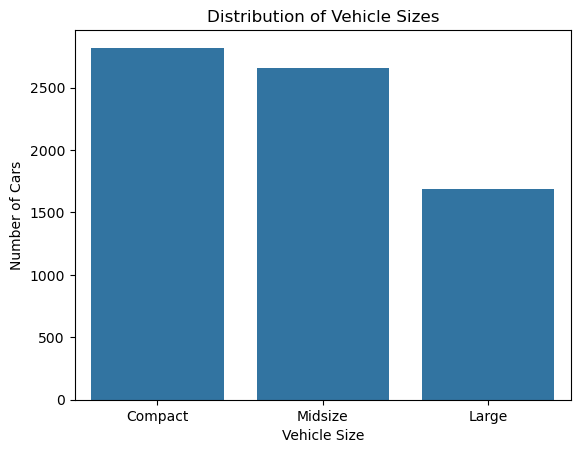

In [71]:
sns.countplot(data=X_train, x="Vehicle Size")

plt.title("Distribution of Vehicle Sizes")
plt.xlabel("Vehicle Size")
plt.ylabel("Number of Cars")
plt.show()

### Relationship with Target

Tasks

- Scatterplots
- Correlation heatmap
- Pairplots (selected columns)


In [78]:
# TODO
train_df.select_dtypes(include=["int64", "float64"]).corr()["MSRP"].sort_values(ascending=False)

MSRP                1.000000
Engine HP           0.665191
Engine Cylinders    0.549922
Year                0.210695
Popularity         -0.047902
Number of Doors    -0.144523
city mpg           -0.171612
highway MPG        -0.188159
Name: MSRP, dtype: float64

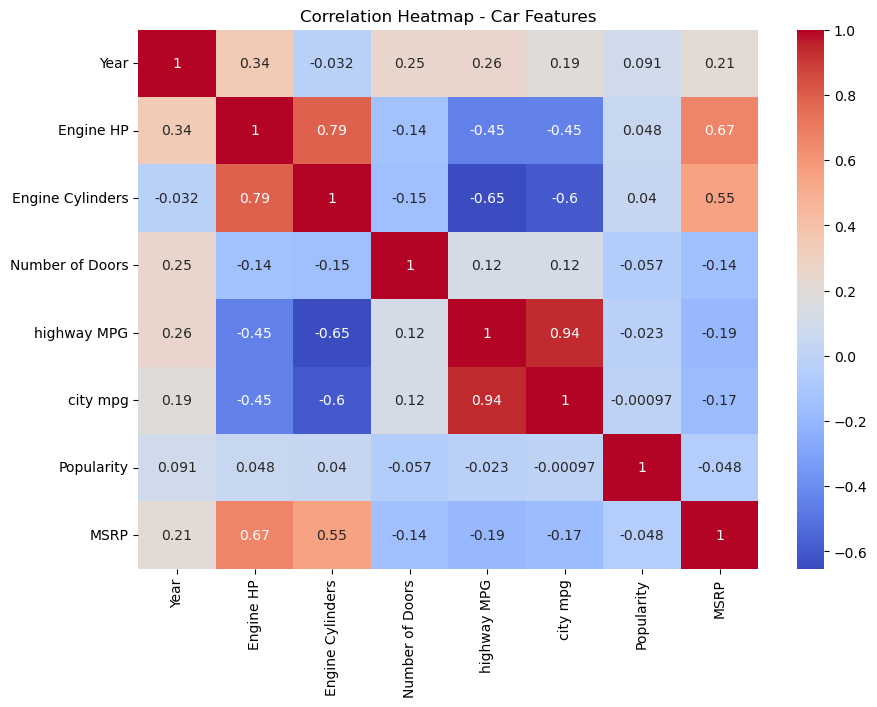

In [80]:
plt.figure(figsize=(10, 7))

sns.heatmap(
    train_df.select_dtypes(include=["int64", "float64"]).corr(),
    annot=True,
    cmap="coolwarm"
)

plt.title("Correlation Heatmap - Car Features")
plt.show()

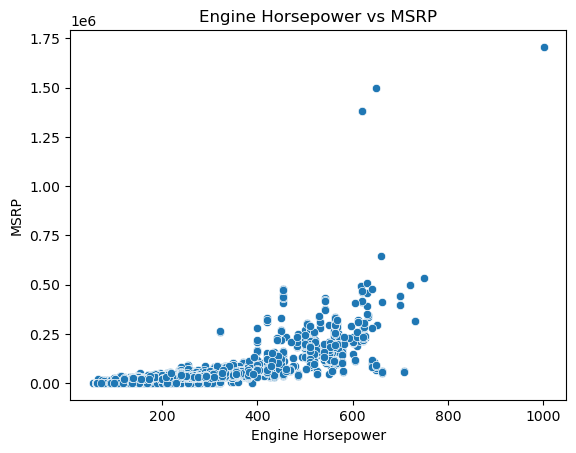

In [82]:
sns.scatterplot(data=train_df, x="Engine HP", y="MSRP")

plt.title("Engine Horsepower vs MSRP")
plt.xlabel("Engine Horsepower")
plt.ylabel("MSRP")
plt.show()

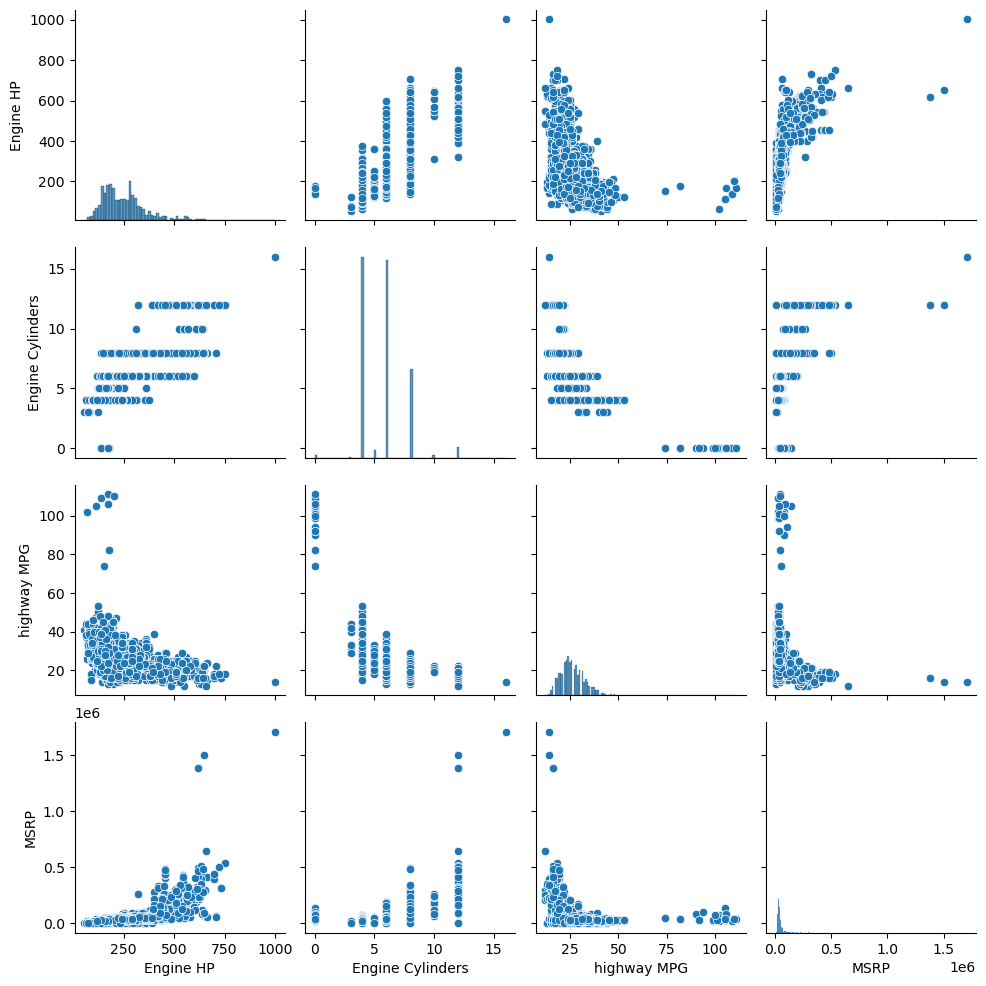

In [84]:
sns.pairplot(
    train_df[["Engine HP", "Engine Cylinders", "highway MPG", "MSRP"]]
)

plt.show()

Questions:

- Which features seem most correlated with price?

# TODO - No Code
### Relationship Between Features and MSRP

Based on the scatterplots and pairplots, Engine Horsepower appears to have the strongest positive relationship with MSRP. Cars with higher horsepower generally have higher prices.

Engine Cylinders also shows a positive relationship with MSRP, as vehicles with larger engines often have higher prices.

Highway MPG appears to have a negative relationship with MSRP, although the pattern is less clear.

The presence of expensive luxury vehicles creates outliers, suggesting that car prices are influenced by additional factors beyond engine specifications.

Overall, Engine Horsepower appears to be an important predictor of MSRP, but the numerical correlation results should also be considered.

In [87]:
train_df.select_dtypes(include=["int64", "float64"]).corr()["MSRP"].sort_values(ascending=False)

MSRP                1.000000
Engine HP           0.665191
Engine Cylinders    0.549922
Year                0.210695
Popularity         -0.047902
Number of Doors    -0.144523
city mpg           -0.171612
highway MPG        -0.188159
Name: MSRP, dtype: float64

## Feature Engineering
Create at least two new features that may improve performance.

Possible ideas

- Engine HP per Cylinder

- Power-to-weight proxy


**You should do the same step for the `val` and `test`**

In [90]:
# TODO
for data in [X_train, X_val, X_test]:
    data["HP_per_Cylinder"] = (
        data["Engine HP"] /
        data["Engine Cylinders"].replace(0, np.nan)
    )

In [91]:
for data in [X_train, X_val, X_test]:
    data["Average_MPG"] = (
        data["city mpg"] + data["highway MPG"]
    ) / 2

In [96]:
X_train[[
    "Engine HP",
    "Engine Cylinders",
    "HP_per_Cylinder",
    "city mpg",
    "highway MPG",
    "Average_MPG"
]].head()

,Engine HP,Engine Cylinders,HP_per_Cylinder,city mpg,highway MPG,Average_MPG
3897,166.0,4.0,41.500000,19,24,21.5
5605,200.0,4.0,50.000000,24,33,28.5
10186,278.0,6.0,46.333333,18,23,20.5
8646,160.0,4.0,40.000000,22,31,26.5
8868,333.0,6.0,55.500000,17,26,21.5


In [98]:
print(X_train[["HP_per_Cylinder", "Average_MPG"]].isnull().sum())

print("Infinite values:",
      np.isinf(X_train[["HP_per_Cylinder", "Average_MPG"]]).sum())

HP_per_Cylinder    70
Average_MPG         0
dtype: int64
Infinite values: HP_per_Cylinder    0
Average_MPG        0
dtype: int64


## Preprocessing
Identify numerical and categorical columns and build a ColumnTransformer.

In [103]:
# TODO
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

In [105]:
numeric_features = X_train.select_dtypes(
    include=["int64", "float64"]
).columns

categorical_features = X_train.select_dtypes(
    include=["object"]
).columns

print("Numerical features:")
print(numeric_features)

print("\nCategorical features:")
print(categorical_features)

Numerical features:
Index(['Year', 'Engine HP', 'Engine Cylinders', 'Number of Doors',
       'highway MPG', 'city mpg', 'Popularity', 'HP_per_Cylinder',
       'Average_MPG'],
      dtype='object')

Categorical features:
Index(['Make', 'Model', 'Engine Fuel Type', 'Transmission Type',
       'Driven_Wheels', 'Market Category', 'Vehicle Size', 'Vehicle Style'],
      dtype='object')


In [107]:
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

In [109]:
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(
        strategy="constant",
        fill_value="Missing"
    )),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

In [111]:
preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, numeric_features),
    ("cat", categorical_pipeline, categorical_features)
])

preprocessor

ColumnTransformer(transformers=[('num',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='median')),
                                                 ('scaler', StandardScaler())]),
                                 Index(['Year', 'Engine HP', 'Engine Cylinders', 'Number of Doors',
       'highway MPG', 'city mpg', 'Popularity', 'HP_per_Cylinder',
       'Average_MPG'],
      dtype='object')),
                                ('cat',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(fill_value='Missing',
                                                                strategy='constant')),
                                                 ('encoder',
                                                  OneHotEncoder(handle_unknown='ignore'))]),
                                 Index(['Make', 'Model', 'Engine Fuel Type', 'Transmission Type',
       'Driven_Wheels', 'Market Category', 'Vehicle Size', 'Vehicle Style'],
      dtype='object'))])

## Pipeline
Create a preprocessing + model pipeline.

In [115]:
# TODO
from sklearn.linear_model import LinearRegression

lr_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", LinearRegression())
])

lr_model

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  Index(['Year', 'Engine HP', 'Engine Cylinders', 'Number of Doors',
       'highway MPG', 'city mpg', 'Popularity', 'HP_per_Cylinder',
       'Average_MPG'],
      dtype='object')),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(fill_value='Missing',
                                                                                 strategy='constant')),
                                                                  ('encoder',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  Index(['Make', 'Model', 'Engine Fuel Type', 'Transmission Type',
       'Driven_Wheels', 'Market Category', 'Vehicle Size', 'Vehicle Style'],
      dtype='object'))])),
                ('model', LinearRegression())])

In [118]:
from sklearn.metrics import mean_absolute_error, mean_squared_error

import numpy as np

## Baseline Model
Train a Linear Regression model and evaluate using MAE, RMSE and MSE.

In [124]:
# TODO
lr_model.fit(X_train, y_train)

lr_predictions = lr_model.predict(X_val)

How well does Linear Regression perform?

In [127]:
# TODO
mae = mean_absolute_error(y_val, lr_predictions)

mse = mean_squared_error(y_val, lr_predictions)

rmse = np.sqrt(mse)

print("Linear Regression Results")
print("MAE:", mae)
print("MSE:", mse)
print("RMSE:", rmse)

Linear Regression Results
MAE: 4230.021174742994
MSE: 119631177.85970248
RMSE: 10937.603844522002


## Model Comparison
Compare at least two regression models.

In [130]:
# TODO
from sklearn.tree import DecisionTreeRegressor

dt_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", DecisionTreeRegressor(
        max_depth=10,
        random_state=42
    ))
])

dt_model.fit(X_train, y_train)

dt_predictions = dt_model.predict(X_val)

In [132]:
dt_mae = mean_absolute_error(y_val, dt_predictions)
dt_mse = mean_squared_error(y_val, dt_predictions)
dt_rmse = np.sqrt(dt_mse)

print("Decision Tree Results")
print("MAE:", dt_mae)
print("MSE:", dt_mse)
print("RMSE:", dt_rmse)

Decision Tree Results
MAE: 5835.939123438081
MSE: 362620600.22458845
RMSE: 19042.599618344877


In [135]:
from sklearn.ensemble import RandomForestRegressor

rf_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", RandomForestRegressor(
        n_estimators=100,
        max_depth=10,
        random_state=42,
        n_jobs=-1
    ))
])

rf_model.fit(X_train, y_train)

rf_predictions = rf_model.predict(X_val)

In [136]:
rf_mae = mean_absolute_error(y_val, rf_predictions)
rf_mse = mean_squared_error(y_val, rf_predictions)
rf_rmse = np.sqrt(rf_mse)

print("Random Forest Results")
print("MAE:", rf_mae)
print("MSE:", rf_mse)
print("RMSE:", rf_rmse)

Random Forest Results
MAE: 4765.830837732612
MSE: 118016836.57885708
RMSE: 10863.555429915985


In [137]:
comparison = pd.DataFrame({
    "Model": ["Linear Regression", "Decision Tree", "Random Forest"],
    "MAE": [mae, dt_mae, rf_mae],
    "MSE": [mse, dt_mse, rf_mse],
    "RMSE": [rmse, dt_rmse, rf_rmse]
})

comparison.sort_values("MAE")

,Model,MAE,MSE,RMSE
0,Linear Regression,4230.021175,1.196312e+08,10937.603845
2,Random Forest,4765.830838,1.180168e+08,10863.555430
1,Decision Tree,5835.939123,3.626206e+08,19042.599618


## Hyperparameter Tuning
Tune your best model using GridSearchCV.

In [141]:
# TODO
from sklearn.model_selection import GridSearchCV

In [142]:
param_grid = {
    "model__n_estimators": [50, 100],
    "model__max_depth": [5, 10, None],
    "model__min_samples_split": [2, 5]
}

In [148]:
grid_search = GridSearchCV(
    estimator=rf_model,
    param_grid=param_grid,
    scoring="neg_mean_absolute_error",
    cv=3,
    n_jobs=-1
)

In [150]:
grid_search.fit(X_train, y_train)

print("Best Parameters:", grid_search.best_params_)
print("Best CV MAE:", -grid_search.best_score_)

Best Parameters: {'model__max_depth': None, 'model__min_samples_split': 5, 'model__n_estimators': 50}
Best CV MAE: 4135.173750592691


Repeat using RandomizedSearchCV.

In [156]:
# TODO
best_grid_model = grid_search.best_estimator_

grid_predictions = best_grid_model.predict(X_val)

grid_mae = mean_absolute_error(y_val, grid_predictions)
grid_mse = mean_squared_error(y_val, grid_predictions)
grid_rmse = np.sqrt(grid_mse)

print("GridSearchCV Results")
print("MAE:", grid_mae)
print("MSE:", grid_mse)
print("RMSE:", grid_rmse)

GridSearchCV Results
MAE: 3517.69986345983
MSE: 92804307.96469839
RMSE: 9633.499258561158


In [157]:
from sklearn.model_selection import RandomizedSearchCV

In [158]:
random_param_grid = {
    "model__n_estimators": [50, 100, 150],
    "model__max_depth": [5, 10, 15, None],
    "model__min_samples_split": [2, 5, 10],
    "model__min_samples_leaf": [1, 2, 4]
}

In [159]:
random_search = RandomizedSearchCV(
    estimator=rf_model,
    param_distributions=random_param_grid,
    n_iter=10,
    scoring="neg_mean_absolute_error",
    cv=3,
    random_state=42,
    n_jobs=1
)

random_search.fit(X_train, y_train)

print("Best Parameters:", random_search.best_params_)
print("Best CV MAE:", -random_search.best_score_)

Best Parameters: {'model__n_estimators': 150, 'model__min_samples_split': 2, 'model__min_samples_leaf': 1, 'model__max_depth': None}
Best CV MAE: 4144.036833599901


In [160]:
best_random_model = random_search.best_estimator_

random_predictions = best_random_model.predict(X_val)

random_mae = mean_absolute_error(y_val, random_predictions)
random_mse = mean_squared_error(y_val, random_predictions)
random_rmse = np.sqrt(random_mse)

print("RandomizedSearchCV Validation Results")
print("MAE:", random_mae)
print("MSE:", random_mse)
print("RMSE:", random_rmse)

RandomizedSearchCV Validation Results
MAE: 3515.1261474063613
MSE: 94650851.97413884
RMSE: 9728.866941948525


Which method was faster? Did both produce similar results?

In [162]:
# TODO
tuning_comparison = pd.DataFrame({
    "Method": ["GridSearchCV", "RandomizedSearchCV"],
    "MAE": [grid_mae, random_mae],
    "RMSE": [grid_rmse, random_rmse]
})

tuning_comparison.sort_values("MAE")

,Method,MAE,RMSE
1,RandomizedSearchCV,3515.126147,9728.866942
0,GridSearchCV,3517.699863,9633.499259


### Hyperparameter Tuning Comparison

GridSearchCV evaluated 12 parameter combinations using 3-fold cross-validation, while RandomizedSearchCV evaluated 10 combinations using 3-fold cross-validation.

RandomizedSearchCV required fewer model fits, although actual execution times were not measured, so we cannot confirm which method was faster.

Both methods produced very similar validation results.

- **GridSearchCV:** MAE = $3,517.70, RMSE = $9,633.50
- **RandomizedSearchCV:** MAE = $3,515.13, RMSE = $9,728.87

RandomizedSearchCV achieved a slightly lower MAE, while GridSearchCV achieved a slightly lower RMSE.

Since MAE is our primary metric, RandomizedSearchCV was selected for further analysis.

## Error Analysis

Predict on validation set

In [166]:
# TODO
best_model = random_search.best_estimator_

val_predictions = best_model.predict(X_val)

Compute residuals

`Actual - Predicted`

In [169]:
# TODO
residuals = y_val - val_predictions

Plot residuals, Predicted vs Actual, investigate largest errors.

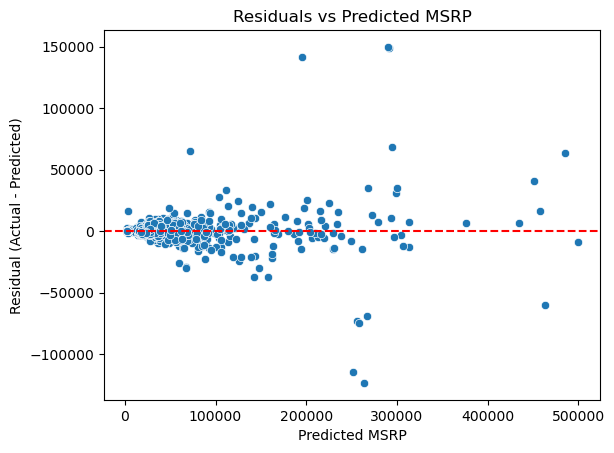

In [171]:
sns.scatterplot(x=val_predictions, y=residuals)

plt.axhline(y=0, color="red", linestyle="--")
plt.title("Residuals vs Predicted MSRP")
plt.xlabel("Predicted MSRP")
plt.ylabel("Residual (Actual - Predicted)")
plt.show()

In [172]:
error_df = X_val[["Make", "Model", "Year"]].copy()

error_df["Actual_MSRP"] = y_val
error_df["Predicted_MSRP"] = val_predictions
error_df["Residual"] = residuals
error_df["Absolute_Error"] = abs(residuals)

error_df.head()

,Make,Model,Year,Actual_MSRP,Predicted_MSRP,Residual,Absolute_Error
11205,Nissan,Van,1990,2000,2000.806667,-0.806667,0.806667
7413,Chrysler,Pacifica,2017,37895,31596.903439,6298.096561,6298.096561
882,Saab,9000,1997,2122,2063.409556,58.590444,58.590444
2862,Bentley,Continental GT,2015,250100,234651.633333,15448.366667,15448.366667
421,BMW,4 Series Gran Coupe,2017,48300,49086.530952,-786.530952,786.530952


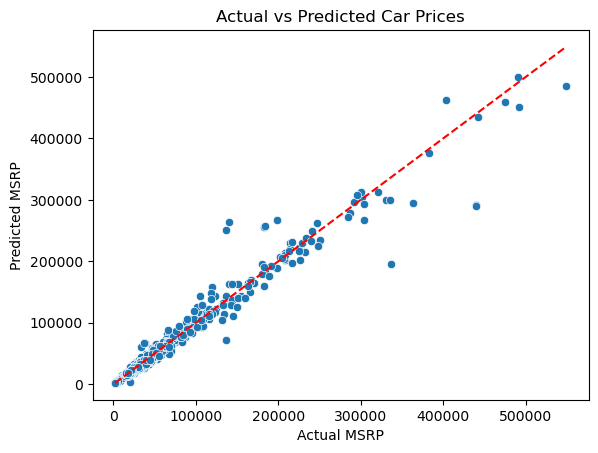

In [173]:
sns.scatterplot(x=y_val, y=val_predictions)

plt.plot(
    [y_val.min(), y_val.max()],
    [y_val.min(), y_val.max()],
    color="red",
    linestyle="--"
)

plt.title("Actual vs Predicted Car Prices")
plt.xlabel("Actual MSRP")
plt.ylabel("Predicted MSRP")
plt.show()

- Where does the model fail?

In [175]:
#TODO-NO CODE

Which cars have the highest prediction errors?

In [177]:
#TODO-NO CODE
error_df.sort_values(
    "Absolute_Error",
    ascending=False
).head(10)

,Make,Model,Year,Actual_MSRP,Predicted_MSRP,Residual,Absolute_Error
2339,Porsche,Carrera GT,2004,440000,290197.960000,149802.040000,149802.040000
2340,Porsche,Carrera GT,2005,440000,290996.366667,149003.633333,149003.633333
2858,Bentley,Continental GT3-R,2015,337000,195564.800000,141435.200000,141435.200000
5072,Mercedes-Benz,G-Class,2016,139900,263318.846667,-123418.846667,123418.846667
5070,Mercedes-Benz,G-Class,2015,137100,251467.893333,-114367.893333,114367.893333
11098,Aston Martin,V12 Vantage S,2016,183695,258134.018333,-74439.018333,74439.018333
11096,Aston Martin,V12 Vantage S,2015,182395,255594.101667,-73199.101667,73199.101667
11097,Aston Martin,V12 Vantage S,2016,198195,267296.731111,-69101.731111,69101.731111
1676,Bentley,Azure T,2010,363000,294731.820000,68268.180000,68268.180000
1398,BMW,Alpina,2003,136900,71869.138889,65030.861111,65030.861111


Are expensive cars harder to predict?

In [179]:
#TODO-NO CODE
error_df["Price_Group"] = pd.cut(
    error_df["Actual_MSRP"],
    bins=[0, 20000, 50000, 100000, float("inf")],
    labels=["Under 20k", "20k-50k", "50k-100k", "Above 100k"]
)

error_df.groupby("Price_Group", observed=True)["Absolute_Error"].mean()

Price_Group
Under 20k       644.345641
20k-50k        2567.871925
50k-100k       4785.908665
Above 100k    20366.480478
Name: Absolute_Error, dtype: float64

## Final Test Evaluation
Evaluate **only once** on the held-out test set.

In [181]:
# TODO
final_model = random_search.best_estimator_

In [182]:
test_predictions = final_model.predict(X_test)

In [183]:
test_mae = mean_absolute_error(y_test, test_predictions)
test_mse = mean_squared_error(y_test, test_predictions)
test_rmse = np.sqrt(test_mse)

print("Final Test Results")
print("MAE:", test_mae)
print("MSE:", test_mse)
print("RMSE:", test_rmse)

Final Test Results
MAE: 3634.470453981688
MSE: 377799704.04730004
RMSE: 19437.070356596952


In [184]:
final_comparison = pd.DataFrame({
    "Dataset": ["Validation", "Test"],
    "MAE": [random_mae, test_mae],
    "RMSE": [random_rmse, test_rmse]
})

final_comparison

,Dataset,MAE,RMSE
0,Validation,3515.126147,9728.866942
1,Test,3634.470454,19437.070357


## Deployment
Deploy your model using streamlit

*You can refer to the class notebook*

In [188]:
import joblib

joblib.dump(final_model, "car_price_model.pkl")

['car_price_model.pkl']

In [189]:
print("Model input features:")
print(final_model.feature_names_in_)

Model input features:
['Make' 'Model' 'Year' 'Engine Fuel Type' 'Engine HP' 'Engine Cylinders'
 'Transmission Type' 'Driven_Wheels' 'Number of Doors' 'Market Category'
 'Vehicle Size' 'Vehicle Style' 'highway MPG' 'city mpg' 'Popularity'
 'HP_per_Cylinder' 'Average_MPG']


In [190]:
saved_model = joblib.load("car_price_model.pkl")

print("Model loaded successfully!")
print(type(saved_model))

Model loaded successfully!
<class 'sklearn.pipeline.Pipeline'>


In [191]:
!python -m pip show streamlit

Name: streamlit
Version: 1.32.0
Summary: A faster way to build and share data apps
Home-page: https://streamlit.io
Author: Snowflake Inc
Author-email: hello@streamlit.io
License: Apache License 2.0
Location: C:\Users\USER\anaconda3\Lib\site-packages
Requires: altair, blinker, cachetools, click, gitpython, numpy, packaging, pandas, pillow, protobuf, pyarrow, pydeck, requests, rich, tenacity, toml, tornado, typing-extensions, watchdog
Required-by: 


In [192]:
%pip install streamlit

Note: you may need to restart the kernel to use updated packages.


In [193]:
import streamlit as st

print("Streamlit version:", st.__version__)

Streamlit version: 1.32.0


In [194]:
categorical_options = {}

for col in categorical_features:
    categorical_options[col] = sorted(
        X_train[col].dropna().unique().tolist()
    )

joblib.dump(categorical_options, "car_categories.pkl")

print("Category options saved!")

Category options saved!


In [195]:
import os

print("Current folder:", os.getcwd())
print("Model exists:", os.path.exists("car_price_model.pkl"))
print("Categories exist:", os.path.exists("car_categories.pkl"))

Current folder: C:\Users\USER\Desktop\Data Science GA\ML_07_Ex
Model exists: True
Categories exist: True


In [196]:
import joblib

folder = r"C:\Users\USER\Desktop\Data Science GA\ML_07_Ex"

joblib.dump(final_model, folder + r"\car_price_model.pkl")

print("Model saved successfully!")

Model saved successfully!


In [232]:
categorical_options = {}

for col in categorical_features:
    categorical_options[col] = sorted(
        X_train[col].dropna().unique().tolist()
    )

joblib.dump(categorical_options, folder + r"\car_categories.pkl")

print("Categories saved successfully!")

Categories saved successfully!


## Reflection
Summarize findings.

- Which preprocessing steps were essential?
- Which model performed best?
- Why?
- Did hyperparameter tuning improve performance?
- Which features contributed most?
- What additional data would improve predictions?
- If this model were deployed in production, what challenges might arise?

In [200]:
# TODO
